In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay

sys.path.insert(0, str(Path.cwd()))

from data import load_data, load_stopwords, make_groups
from evaluation import baseline_predictions, evaluate, split_data
from model import build_model, top_features

data = load_data("../data/processed/headlines.csv")
data["group"] = make_groups(data)
labels = sorted(data["label"].unique())
train_indices, test_indices = split_data(data)
train = data.iloc[train_indices]
test = data.iloc[test_indices]

majority_label, baseline = baseline_predictions(train["label"], len(test))
print(f"majority baseline: {majority_label}")
print(pd.DataFrame(evaluate(test["label"], baseline, labels)["report"]).T[["precision", "recall", "f1-score"]].round(3))

data["label"].value_counts()

majority baseline: vilifying_opponents
                      precision  recall  f1-score
nothing                   0.000   0.000     0.000
personality_cult          0.000   0.000     0.000
vilifying_eu              0.000   0.000     0.000
vilifying_neighbours      0.000   0.000     0.000
vilifying_opponents       0.538   1.000     0.700
accuracy                  0.538   0.538     0.538
macro avg                 0.108   0.200     0.140
weighted avg              0.289   0.538     0.376


label
vilifying_opponents     245
nothing                  84
vilifying_neighbours     69
personality_cult         38
vilifying_eu             19
Name: count, dtype: int64

In [3]:
results = {}
stopword_options = {
    "without stopword labels": None,
    "with Serbian stopword labels": load_stopwords(),
}

for name, stopwords in stopword_options.items():
    model = build_model(stopwords)
    model.fit(train["headline"], train["label"])
    predictions = model.predict(test["headline"])
    results[name] = {
        "model": model,
        "predictions": predictions,
        "metrics": evaluate(test["label"], predictions, labels),
    }
    print(name, len(model.named_steps["tfidf"].vocabulary_))

without stopword labels 7339
with Serbian stopword labels 6374


In [4]:
for name, result in results.items():
    print(f"\n{name}")
    report = pd.DataFrame(result["metrics"]["report"]).T
    display(report[["precision", "recall", "f1-score", "support"]].round(3))


without stopword labels


,precision,recall,f1-score,support
nothing,0.812,0.591,0.684,22.000
personality_cult,0.364,0.571,0.444,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.938,0.750,0.833,20.000
vilifying_opponents,0.742,0.930,0.825,71.000
accuracy,0.742,0.742,0.742,0.742
macro avg,0.571,0.568,0.557,132.000
weighted avg,0.696,0.742,0.708,132.000



with Serbian stopword labels


,precision,recall,f1-score,support
nothing,0.786,0.500,0.611,22.000
personality_cult,0.400,0.857,0.545,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.875,0.350,0.500,20.000
vilifying_opponents,0.695,0.930,0.795,71.000
accuracy,0.682,0.682,0.682,0.682
macro avg,0.551,0.527,0.490,132.000
weighted avg,0.658,0.682,0.634,132.000


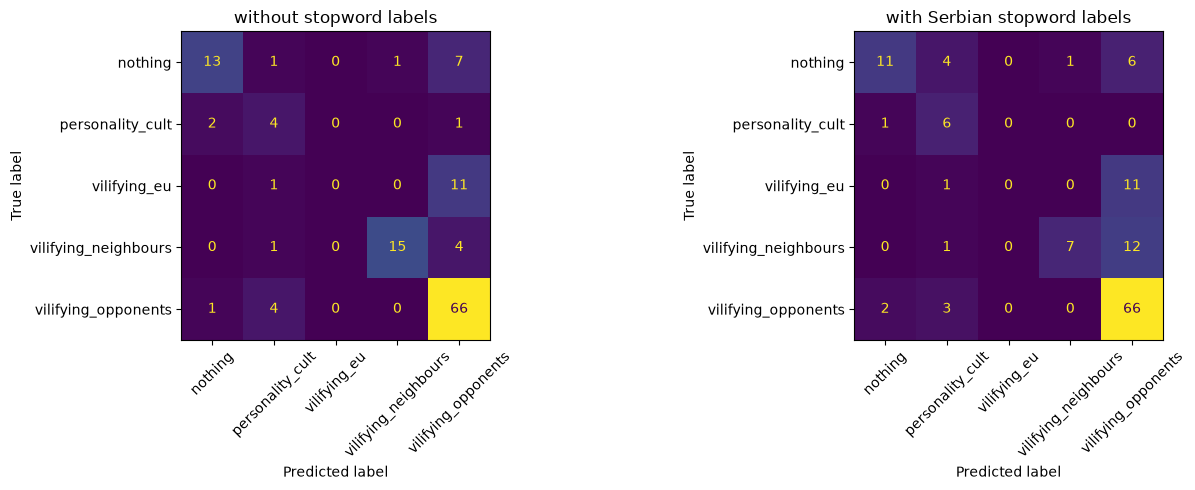

In [5]:
fig, axes = plt.subplots(1, len(results), figsize=(14, 5))
for axis, (name, result) in zip(axes, results.items()):
    ConfusionMatrixDisplay(
        result["metrics"]["confusion_matrix"],
        display_labels=labels,
    ).plot(ax=axis, xticks_rotation=45, colorbar=False)
    axis.set_title(name)
plt.tight_layout()
plt.show()

In [6]:
for name, result in results.items():
    print(f"\n{name}")
    for label, features in top_features(result["model"], limit=8).items():
        print(label, ", ".join(f"{word} ({weight:.2f})" for word, weight in features))


without stopword labels
nothing aleksandar (0.45), aleksandar vučić (0.45), nacionalne (0.44), ujedinjena srbija (0.42), macut (0.41), ujedinjena (0.40), sati (0.39), predsednik (0.38)
personality_cult vučić (1.48), sam (0.52), ponosan (0.48), ima (0.40), evo (0.40), porodica (0.40), video (0.39), ljudi (0.38)
vilifying_eu evrope (0.82), gujon (0.82), iz (0.66), dajte (0.57), dajte novac (0.57), eu dajte (0.57), nama šolaku (0.57), novac nama (0.57)
vilifying_neighbours srba (0.90), hrvati (0.70), progon (0.58), hrvatska (0.53), gazimestanu (0.51), na gazimestanu (0.51), velike (0.49), srbi (0.45)
vilifying_opponents blokaderi (0.93), su (0.41), blokaderi su (0.37), top (0.37), zvučni (0.37), zvučni top (0.37), lažni (0.34), blokadera (0.33)

with Serbian stopword labels
nothing nacionalne (0.48), aleksandar (0.47), aleksandar vučić (0.47), macut (0.44), ujedinjena srbija (0.44), ujedinjena (0.42), sati (0.40), predsednik (0.40)
personality_cult vučić (1.64), vučić stopword (0.65), st

# Logistic regression experiment

TF-IDF creates one sparse feature-vector row per headline. Logistic regression learns how those features map to labels. The same grouped split is used for both stopword conditions.

# Hierarchical model

First differentiate between sentiment: vilifying or glorifying or nothing. This should try to find a "propaganda vibe" in the headline.

Secondary differentiator would be target of vilification: EU, neighbours, or opponents.

In [7]:
# Hierarchical logistic-regression model:
# stage 1: nothing / glorifying / vilifying
# stage 2: target of vilification

sentiment_classes = ["nothing", "glorifying", "vilifying"]
vilifying_labels = [
    "vilifying_eu",
    "vilifying_neighbours",
    "vilifying_opponents",
]


def sentiment_label(label):
    if label == "nothing":
        return "nothing"
    if label == "personality_cult":
        return "glorifying"
    return "vilifying"


hierarchical_results = {}

for name, stopwords in stopword_options.items():
    stage1_train_y = train["label"].map(sentiment_label)
    stage1_test_y = test["label"].map(sentiment_label)

    stage1_model = build_model(stopwords)
    stage1_model.fit(train["headline"], stage1_train_y)

    stage1_predictions = stage1_model.predict(test["headline"])

    vilifying_train = train[
        train["label"].isin(vilifying_labels)
    ]

    stage2_model = build_model(stopwords)
    stage2_model.fit(
        vilifying_train["headline"],
        vilifying_train["label"],
    )

    vilifying_test = test[test["label"].isin(vilifying_labels)]
    stage2_predictions = stage2_model.predict(
        vilifying_test["headline"]
    )

    final_predictions = []
    vilifying_test_indices = [
        index for index, sentiment in enumerate(stage1_predictions)
        if sentiment == "vilifying"
    ]

    if vilifying_test_indices:
        vilifying_headlines = test.iloc[vilifying_test_indices]["headline"]
        predicted_targets = stage2_model.predict(vilifying_headlines)
    else:
        predicted_targets = []

    target_position = 0

    for sentiment in stage1_predictions:
        if sentiment == "nothing":
            final_predictions.append("nothing")
        elif sentiment == "glorifying":
            final_predictions.append("personality_cult")
        else:
            final_predictions.append(predicted_targets[target_position])
            target_position += 1

    stage1_metrics = evaluate(
        stage1_test_y,
        stage1_predictions,
        sentiment_classes,
    )

    stage2_metrics = evaluate(
        vilifying_test["label"],
        stage2_predictions,
        vilifying_labels,
    )

    end_to_end_metrics = evaluate(
        test["label"],
        final_predictions,
        labels,
    )

    hierarchical_results[name] = {
        "stage1_model": stage1_model,
        "stage2_model": stage2_model,
        "stage1_predictions": stage1_predictions,
        "stage2_predictions": stage2_predictions,
        "predictions": final_predictions,
        "stage1_metrics": stage1_metrics,
        "stage2_metrics": stage2_metrics,
        "metrics": end_to_end_metrics,
    }

    print(f"\n{name} — stage 1")
    display(
        pd.DataFrame(stage1_metrics["report"]).T[
            ["precision", "recall", "f1-score", "support"]
        ].round(3)
    )

    print(f"{name} — stage 2")
    display(
        pd.DataFrame(stage2_metrics["report"]).T[
            ["precision", "recall", "f1-score", "support"]
        ].round(3)
    )

    print(f"{name} — end-to-end")
    display(
        pd.DataFrame(end_to_end_metrics["report"]).T[
            ["precision", "recall", "f1-score", "support"]
        ].round(3)
    )


without stopword labels — stage 1


,precision,recall,f1-score,support
nothing,0.800,0.545,0.649,22.000
glorifying,0.333,0.429,0.375,7.000
vilifying,0.898,0.942,0.919,103.000
accuracy,0.848,0.848,0.848,0.848
macro avg,0.677,0.639,0.648,132.000
weighted avg,0.852,0.848,0.845,132.000


without stopword labels — stage 2


,precision,recall,f1-score,support
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,1.000,0.500,0.667,20.000
vilifying_opponents,0.763,1.000,0.866,71.000
accuracy,0.786,0.786,0.786,0.786
macro avg,0.588,0.500,0.511,103.000
weighted avg,0.720,0.786,0.726,103.000


without stopword labels — end-to-end


...

,precision,recall,f1-score,support
nothing,0.769,0.455,0.571,22.000
glorifying,0.545,0.857,0.667,7.000
vilifying,0.898,0.942,0.919,103.000
accuracy,0.856,0.856,0.856,0.856
macro avg,0.738,0.751,0.719,132.000
weighted avg,0.858,0.856,0.848,132.000


with Serbian stopword labels — stage 2


,precision,recall,f1-score,support
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,1.000,0.350,0.519,20.000
vilifying_opponents,0.740,1.000,0.850,71.000
accuracy,0.757,0.757,0.757,0.757
macro avg,0.580,0.450,0.456,103.000
weighted avg,0.704,0.757,0.687,103.000


with Serbian stopword labels — end-to-end


,precision,recall,f1-score,support
nothing,0.769,0.455,0.571,22.000
personality_cult,0.545,0.857,0.667,7.000
vilifying_eu,0.000,0.000,0.000,12.000
vilifying_neighbours,0.875,0.350,0.500,20.000
vilifying_opponents,0.670,0.944,0.784,71.000
accuracy,0.682,0.682,0.682,0.682
macro avg,0.572,0.521,0.504,132.000
weighted avg,0.650,0.682,0.628,132.000


`evaluate()` is mainly for the per-class report (precision/recall/F1/support), not a single “accuracy” score. For overall accuracy, use `sklearn.metrics.accuracy_score`:

```python
from sklearn.metrics import accuracy_score

for name, result in results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    print(f"{name}: accuracy = {acc:.3f}")

for name, result in hierarchical_results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    print(f"{name}: hierarchical accuracy = {acc:.3f}")
```

If your custom `evaluate()` function happens to include an `accuracy` field, you can also inspect:

```python
results["with Serbian stopword labels"]["metrics"].get("accuracy")
```

But for this task, accuracy is not the main metric because the positive class is rare. Precision/recall and ranked precision@k are more informative.

In [8]:
from sklearn.metrics import accuracy_score
import pandas as pd

comparison = []

# Simple TF-IDF logistic regression models
for name, result in results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    comparison.append({
        "model_type": "simple",
        "variant": name,
        "accuracy": acc,
    })

# Hierarchical staged models
for name, result in hierarchical_results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    comparison.append({
        "model_type": "staged",
        "variant": name,
        "accuracy": acc,
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("accuracy", ascending=False))

for name, result in results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    print(f"{name}: simple model accuracy = {acc:.3f}")

for name, result in hierarchical_results.items():
    acc = accuracy_score(test["label"], result["predictions"])
    print(f"{name}: staged model accuracy = {acc:.3f}")

,model_type,variant,accuracy
0,simple,without stopword labels,0.742424
2,staged,without stopword labels,0.696970
1,simple,with Serbian stopword labels,0.681818
3,staged,with Serbian stopword labels,0.681818


without stopword labels: simple model accuracy = 0.742
with Serbian stopword labels: simple model accuracy = 0.682
without stopword labels: staged model accuracy = 0.697
with Serbian stopword labels: staged model accuracy = 0.682
